# Workshop 4: sentiment analysis of IMDB movie reviews

Predict whether a review is negative (0) or positive (1). Complete the movie-review
example, compare epoch counts, hidden-layer widths and depths, and reflect on the
results. The baseline has two 16-unit ReLU hidden layers and one sigmoid output.

**Evaluation plan:** hold out 10,000 of the 25,000 training reviews for validation.
Use validation loss to choose a configuration and epoch, retrain using all training
reviews, and evaluate the selected model once on the separate 25,000-review test set.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.datasets import imdb
from keras import models, layers
from IPython.display import Markdown, display

keras.utils.set_random_seed(42)
VOCAB_SIZE = 10000

## 1. Load and decode a review

Keras provides each review as a variable-length sequence of word IDs, retaining
only the 10,000 most frequent IDs. The labels are binary sentiment targets.
The word index is offset by three because the dataset reserves special IDs.

In [2]:
(trainset, train_labels), (testset, test_labels) = imdb.load_data(num_words=VOCAB_SIZE)
word_index = imdb.get_word_index()
reverse_index = {index: word for word, index in word_index.items()}

def translate(sequence):
    special = {0: '[PAD]', 1: '[START]', 2: '[UNK]'}
    return ' '.join(special.get(index, reverse_index.get(index - 3, '[UNK]'))
                    for index in sequence)

print('Training reviews:', len(trainset), '| test reviews:', len(testset))
print('First review length:', len(trainset[0]))
print('First review IDs:', trainset[0][:25])
print(translate(trainset[0]))
print('Sentiment:', 'positive' if train_labels[0] else 'negative')

Training reviews: 25000 | test reviews: 25000
First review length: 218
First review IDs: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50]
[START] this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert [UNK] is an amazing actor and now the same being director [UNK] father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for [UNK] and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also [UNK] to the two little boy's that played the [UNK] of norman and paul they were just brilliant

## 2. Vectorise the reviews

Multi-hot encoding produces 10,000 features per review: a 1 means that an ID
appears at least once. Repeated words still give 1, so this representation loses
word counts and order. The model therefore cannot directly distinguish phrases
that use the same words in a different order.

Use `float32` to match the model's usual computation type. One 25,000 by 10,000
array occupies about 1 GB instead of the 2 GB required by NumPy's default `float64`.
The test matrix is prepared only at the final evaluation.

In [3]:
def vectorize(sequences, dimension=VOCAB_SIZE):
    results = np.zeros((len(sequences), dimension), dtype='float32')
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results

# A small check makes the encoding rule visible before allocating the full matrix.
print(vectorize([[1, 3, 3], [2]], dimension=5))
x_train = vectorize(trainset)
y_train = np.asarray(train_labels, dtype='float32')
print('Training input:', x_train.shape, x_train.dtype)
print(f'Input matrix memory: {x_train.nbytes / 1e9:.2f} GB')

[[0. 1. 0. 1. 0.]
 [0. 0. 1. 0. 0.]]
Training input: (25000, 10000) float32
Input matrix memory: 1.00 GB


## 3. Hold out a validation set

The dataset loader already shuffles the reviews using a fixed seed. Reserve the
first 10,000 for validation and use the remaining 15,000 for learning. Slicing
creates views here, so it does not duplicate the full matrix. Every experiment
uses the same split. Test reviews do not participate in this selection.

In [4]:
x_val, y_val = x_train[:10000], y_train[:10000]
partial_x_train, partial_y_train = x_train[10000:], y_train[10000:]
print('Training subset:', partial_x_train.shape)
print('Validation:     ', x_val.shape)
print(f'Positive fraction: training {partial_y_train.mean():.3f}, validation {y_val.mean():.3f}')

Training subset: (15000, 10000)
Validation:      (10000, 10000)
Positive fraction: training 0.496, validation 0.505


## 4. Build and compile the baseline

ReLU hidden layers learn features. A single sigmoid output gives a score between
0 and 1; use a threshold of 0.5 for the binary decision. Binary cross-entropy fits
the binary labels. RMSprop updates the weights. The baseline has 160,305 parameters.

In [5]:
def build_network(hidden_layers=(16, 16)):
    model = models.Sequential([layers.Input(shape=(VOCAB_SIZE,))])
    for units in hidden_layers:
        model.add(layers.Dense(units, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

network = build_network()
network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train with validation and compare networks

Create a fresh model for every run. Fix the random seed, example split, learning
rate and batch size (512), and vary one factor at a time. For different depths,
keep every hidden layer at 16 units; for width, keep two hidden layers.

| Run | Hidden units | Epochs | Purpose |
|---|---|---|---|
| A | 16, 16 | 10 | Baseline |
| B | 16, 16 | 4 | Fewer epochs |
| C | 16, 16 | 20 | More epochs |
| D | 8, 8 | 10 | Narrower layers |
| E | 32, 32 | 10 | Wider layers |
| F | 16 | 10 | One hidden layer |
| G | 16, 16, 16 | 10 | Three hidden layers |

In [6]:
def run_experiment(name, hidden_layers=(16, 16), epochs=10):
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    model = build_network(hidden_layers)
    print(name)
    history = model.fit(partial_x_train, partial_y_train, epochs=epochs, batch_size=512,
                        validation_data=(x_val, y_val), verbose=2).history
    best_epoch = int(np.argmin(history['val_loss'])) + 1
    return {
        'name': name, 'hidden_layers': hidden_layers, 'epochs': epochs,
        'parameters': model.count_params(), 'history': history,
        'best_epoch': best_epoch, 'best_val_loss': history['val_loss'][best_epoch - 1],
    }

results = {}
results['A'] = run_experiment('A: baseline')

A: baseline
Epoch 1/10
30/30 - 1s - 26ms/step - accuracy: 0.7762 - loss: 0.5288 - val_accuracy: 0.8646 - val_loss: 0.3964
Epoch 2/10
30/30 - 0s - 5ms/step - accuracy: 0.8901 - loss: 0.3252 - val_accuracy: 0.8843 - val_loss: 0.3092
Epoch 3/10
30/30 - 0s - 6ms/step - accuracy: 0.9209 - loss: 0.2385 - val_accuracy: 0.8825 - val_loss: 0.2947
Epoch 4/10
30/30 - 0s - 8ms/step - accuracy: 0.9347 - loss: 0.1967 - val_accuracy: 0.8877 - val_loss: 0.2767
Epoch 5/10
30/30 - 0s - 5ms/step - accuracy: 0.9442 - loss: 0.1659 - val_accuracy: 0.8856 - val_loss: 0.2789
Epoch 6/10
30/30 - 0s - 7ms/step - accuracy: 0.9549 - loss: 0.1402 - val_accuracy: 0.8848 - val_loss: 0.2874
Epoch 7/10
30/30 - 0s - 10ms/step - accuracy: 0.9628 - loss: 0.1208 - val_accuracy: 0.8839 - val_loss: 0.2968
Epoch 8/10
30/30 - 0s - 7ms/step - accuracy: 0.9698 - loss: 0.1022 - val_accuracy: 0.8815 - val_loss: 0.3111
Epoch 9/10
30/30 - 0s - 6ms/step - accuracy: 0.9736 - loss: 0.0899 - val_accuracy: 0.8814 - val_loss: 0.3262
Epoch

## 6. Plot training against validation

The training and validation losses belong on the same plot; accuracy has a separate
plot. If training loss keeps falling while validation loss rises, the network is
fitting the training examples more closely without improving generalisation.
The validation-loss minimum gives an epoch to consider when retraining.

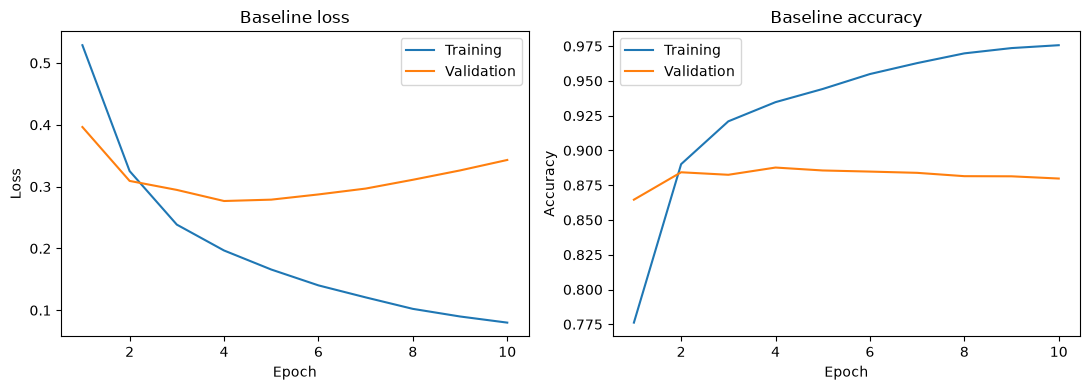

In [7]:
hist = results['A']['history']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    epochs = range(1, len(hist[metric]) + 1)
    ax.plot(epochs, hist[metric], label='Training')
    ax.plot(epochs, hist['val_' + metric], label='Validation')
    ax.set(xlabel='Epoch', ylabel=metric.capitalize(), title='Baseline ' + metric)
    ax.legend()
fig.tight_layout()
plt.show()

In [8]:
results['B'] = run_experiment('B: 4 epochs', epochs=4)
results['C'] = run_experiment('C: 20 epochs', epochs=20)

B: 4 epochs
Epoch 1/4
30/30 - 1s - 22ms/step - accuracy: 0.7762 - loss: 0.5288 - val_accuracy: 0.8646 - val_loss: 0.3964
Epoch 2/4
30/30 - 0s - 5ms/step - accuracy: 0.8901 - loss: 0.3252 - val_accuracy: 0.8843 - val_loss: 0.3092
Epoch 3/4
30/30 - 0s - 4ms/step - accuracy: 0.9209 - loss: 0.2385 - val_accuracy: 0.8825 - val_loss: 0.2947
Epoch 4/4
30/30 - 0s - 5ms/step - accuracy: 0.9347 - loss: 0.1967 - val_accuracy: 0.8877 - val_loss: 0.2767
C: 20 epochs
Epoch 1/20
30/30 - 0s - 15ms/step - accuracy: 0.7762 - loss: 0.5288 - val_accuracy: 0.8646 - val_loss: 0.3964
Epoch 2/20
30/30 - 0s - 4ms/step - accuracy: 0.8901 - loss: 0.3252 - val_accuracy: 0.8843 - val_loss: 0.3092
Epoch 3/20
30/30 - 0s - 5ms/step - accuracy: 0.9209 - loss: 0.2385 - val_accuracy: 0.8825 - val_loss: 0.2947
Epoch 4/20
30/30 - 0s - 5ms/step - accuracy: 0.9347 - loss: 0.1967 - val_accuracy: 0.8877 - val_loss: 0.2767
Epoch 5/20
30/30 - 0s - 5ms/step - accuracy: 0.9442 - loss: 0.1659 - val_accuracy: 0.8856 - val_loss: 0.2

In [9]:
results['D'] = run_experiment('D: narrower layers', hidden_layers=(8, 8))
results['E'] = run_experiment('E: wider layers', hidden_layers=(32, 32))

D: narrower layers
Epoch 1/10
30/30 - 0s - 16ms/step - accuracy: 0.7596 - loss: 0.5689 - val_accuracy: 0.8431 - val_loss: 0.4587
Epoch 2/10
30/30 - 0s - 4ms/step - accuracy: 0.8857 - loss: 0.3803 - val_accuracy: 0.8711 - val_loss: 0.3601
Epoch 3/10
30/30 - 0s - 4ms/step - accuracy: 0.9108 - loss: 0.2897 - val_accuracy: 0.8837 - val_loss: 0.3122
Epoch 4/10
30/30 - 0s - 4ms/step - accuracy: 0.9252 - loss: 0.2340 - val_accuracy: 0.8862 - val_loss: 0.2888
Epoch 5/10
30/30 - 0s - 4ms/step - accuracy: 0.9371 - loss: 0.1956 - val_accuracy: 0.8877 - val_loss: 0.2785
Epoch 6/10
30/30 - 0s - 4ms/step - accuracy: 0.9475 - loss: 0.1673 - val_accuracy: 0.8874 - val_loss: 0.2774
Epoch 7/10
30/30 - 0s - 4ms/step - accuracy: 0.9558 - loss: 0.1451 - val_accuracy: 0.8859 - val_loss: 0.2814
Epoch 8/10
30/30 - 0s - 4ms/step - accuracy: 0.9628 - loss: 0.1262 - val_accuracy: 0.8834 - val_loss: 0.2890
Epoch 9/10
30/30 - 0s - 4ms/step - accuracy: 0.9701 - loss: 0.1093 - val_accuracy: 0.8830 - val_loss: 0.3000

In [10]:
results['F'] = run_experiment('F: one hidden layer', hidden_layers=(16,))
results['G'] = run_experiment('G: three hidden layers', hidden_layers=(16, 16, 16))

F: one hidden layer
Epoch 1/10
30/30 - 1s - 18ms/step - accuracy: 0.7971 - loss: 0.5104 - val_accuracy: 0.8604 - val_loss: 0.4065
Epoch 2/10
30/30 - 0s - 5ms/step - accuracy: 0.8925 - loss: 0.3416 - val_accuracy: 0.8795 - val_loss: 0.3359
Epoch 3/10
30/30 - 0s - 5ms/step - accuracy: 0.9131 - loss: 0.2721 - val_accuracy: 0.8849 - val_loss: 0.3035
Epoch 4/10
30/30 - 0s - 5ms/step - accuracy: 0.9271 - loss: 0.2293 - val_accuracy: 0.8875 - val_loss: 0.2873
Epoch 5/10
30/30 - 0s - 4ms/step - accuracy: 0.9370 - loss: 0.1997 - val_accuracy: 0.8877 - val_loss: 0.2794
Epoch 6/10
30/30 - 0s - 4ms/step - accuracy: 0.9441 - loss: 0.1776 - val_accuracy: 0.8874 - val_loss: 0.2772
Epoch 7/10
30/30 - 0s - 4ms/step - accuracy: 0.9503 - loss: 0.1598 - val_accuracy: 0.8855 - val_loss: 0.2779
Epoch 8/10
30/30 - 0s - 4ms/step - accuracy: 0.9563 - loss: 0.1447 - val_accuracy: 0.8842 - val_loss: 0.2810
Epoch 9/10
30/30 - 0s - 4ms/step - accuracy: 0.9613 - loss: 0.1316 - val_accuracy: 0.8830 - val_loss: 0.285

## 7. Compare the results

Final-epoch scores show what happens when each run uses its whole epoch budget.
Best-epoch columns record the lowest validation loss within the run. Selecting
by loss uses the confidence of predictions as well as whether they are correct.
A higher accuracy need not imply a lower cross-entropy loss.

In [11]:
header = '| Experiment | Hidden units | Epochs | Parameters | Final train acc | Final val acc | Final val loss | Best epoch | Best val loss |'
rows = [header, '|' + '---|' * 9]
for r in results.values():
    h = r['history']
    rows.append(f"| {r['name']} | {r['hidden_layers']} | {r['epochs']} | {r['parameters']:,} | "
                f"{h['accuracy'][-1]:.4f} | {h['val_accuracy'][-1]:.4f} | "
                f"{h['val_loss'][-1]:.4f} | {r['best_epoch']} | {r['best_val_loss']:.4f} |")
display(Markdown('\n'.join(rows)))

| Experiment | Hidden units | Epochs | Parameters | Final train acc | Final val acc | Final val loss | Best epoch | Best val loss |
|---|---|---|---|---|---|---|---|---|
| A: baseline | (16, 16) | 10 | 160,305 | 0.9757 | 0.8798 | 0.3431 | 4 | 0.2767 |
| B: 4 epochs | (16, 16) | 4 | 160,305 | 0.9347 | 0.8877 | 0.2767 | 4 | 0.2767 |
| C: 20 epochs | (16, 16) | 20 | 160,305 | 0.9971 | 0.8699 | 0.5535 | 4 | 0.2767 |
| D: narrower layers | (8, 8) | 10 | 80,089 | 0.9739 | 0.8825 | 0.3131 | 6 | 0.2774 |
| E: wider layers | (32, 32) | 10 | 321,121 | 0.9771 | 0.8763 | 0.3691 | 4 | 0.2769 |
| F: one hidden layer | (16,) | 10 | 160,033 | 0.9661 | 0.8829 | 0.2916 | 6 | 0.2772 |
| G: three hidden layers | (16, 16, 16) | 10 | 160,577 | 0.9801 | 0.8792 | 0.3722 | 4 | 0.2767 |

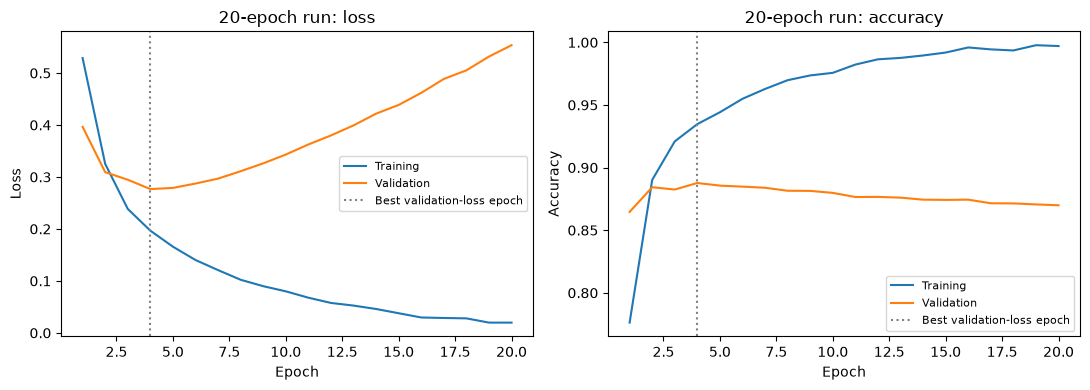

In [12]:
h = results['C']['history']
epochs = range(1, len(h['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ['loss', 'accuracy']):
    ax.plot(epochs, h[metric], label='Training')
    ax.plot(epochs, h['val_' + metric], label='Validation')
    ax.axvline(results['C']['best_epoch'], color='gray', linestyle=':', label='Best validation-loss epoch')
    ax.set(xlabel='Epoch', ylabel=metric.capitalize(), title='20-epoch run: ' + metric)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8. Retrain the selected configuration and evaluate the test set

Choose the configuration and epoch with the lowest validation loss. Start with
fresh weights and train using all 25,000 training reviews. The validation examples
can now join training because model selection is finished. The separate test set
provides the final generalisation measurement.

In [13]:
best = min(results.values(), key=lambda r: r['best_val_loss'])
print(f"Selected {best['name']}, epoch {best['best_epoch']}, validation loss {best['best_val_loss']:.4f}")
keras.backend.clear_session()
keras.utils.set_random_seed(42)
final_model = build_network(best['hidden_layers'])
final_model.fit(x_train, y_train, epochs=best['best_epoch'], batch_size=512, verbose=2)
x_test = vectorize(testset)
y_test = np.asarray(test_labels, dtype='float32')
test_loss, test_acc = final_model.evaluate(x_test, y_test, batch_size=512, verbose=0)
print(f'Final test loss: {test_loss:.4f}')
print(f'Final test accuracy: {test_acc:.2%}')

Selected A: baseline, epoch 4, validation loss 0.2767
Epoch 1/4
49/49 - 0s - 10ms/step - accuracy: 0.8108 - loss: 0.4685
Epoch 2/4
49/49 - 0s - 3ms/step - accuracy: 0.9020 - loss: 0.2769
Epoch 3/4
49/49 - 0s - 3ms/step - accuracy: 0.9246 - loss: 0.2141
Epoch 4/4
49/49 - 0s - 4ms/step - accuracy: 0.9352 - loss: 0.1831
Final test loss: 0.2899
Final test accuracy: 88.36%


In [14]:
probabilities = final_model.predict(x_test[:10], verbose=0).ravel()
print('P(positive):', np.round(probabilities, 3))
print('Predicted:  ', (probabilities >= 0.5).astype(int))
print('Actual:     ', test_labels[:10])

P(positive): [0.299 0.999 0.855 0.785 0.937 0.748 0.999 0.014 0.969 0.994]
Predicted:   [0 1 1 1 1 1 1 0 1 1]
Actual:      [0 1 1 0 1 1 1 0 0 1]


## 9. Reflection on the measured results

In [15]:
a, c = results['A'], results['C']
width_best = min((results[k] for k in ['A', 'D', 'E']), key=lambda r: r['best_val_loss'])
depth_best = min((results[k] for k in ['A', 'F', 'G']), key=lambda r: r['best_val_loss'])
display(Markdown(f"""
- **Training is not testing:** the baseline finishes with training accuracy {a['history']['accuracy'][-1]:.2%}, but validation accuracy {a['history']['val_accuracy'][-1]:.2%}. The training score describes reviews used for weight updates.
- **Epochs:** the 20-epoch run's lowest validation loss occurs at epoch {c['best_epoch']}. By epoch 20, training loss is {c['history']['loss'][-1]:.4f} and validation loss is {c['history']['val_loss'][-1]:.4f}. Compare the curves: further training can improve the training fit while validation performance deteriorates.
- **Width:** among the two-layer networks with 8, 16 and 32 units per layer, {width_best['name']} has the lowest observed validation loss ({width_best['best_val_loss']:.4f}). Wider layers add parameters, so more capacity is not automatically a better choice.
- **Depth:** among one, two and three 16-unit hidden layers, {depth_best['name']} has the lowest observed validation loss ({depth_best['best_val_loss']:.4f}). This comparison records what extra depth achieved for this representation and split.
- **Final selection:** {best['name']} at epoch {best['best_epoch']} wins by validation loss. Retraining it on all training reviews produces **{test_acc:.2%} test accuracy** and test loss **{test_loss:.4f}**.
- **Representation limits:** multi-hot vectors discard word order and counts. A high score does not mean the model understands every negation or ambiguous review, and sigmoid scores are not guaranteed to be calibrated probabilities.
- **Evidence limits:** these are single-seed experiments on a fixed validation split. Small differences may change with different seeds or splits. More trials would be needed to claim a reliable ranking. The test set was kept out of model selection.
"""))


- **Training is not testing:** the baseline finishes with training accuracy 97.57%, but validation accuracy 87.98%. The training score describes reviews used for weight updates.
- **Epochs:** the 20-epoch run's lowest validation loss occurs at epoch 4. By epoch 20, training loss is 0.0198 and validation loss is 0.5535. Compare the curves: further training can improve the training fit while validation performance deteriorates.
- **Width:** among the two-layer networks with 8, 16 and 32 units per layer, A: baseline has the lowest observed validation loss (0.2767). Wider layers add parameters, so more capacity is not automatically a better choice.
- **Depth:** among one, two and three 16-unit hidden layers, A: baseline has the lowest observed validation loss (0.2767). This comparison records what extra depth achieved for this representation and split.
- **Final selection:** A: baseline at epoch 4 wins by validation loss. Retraining it on all training reviews produces **88.36% test accuracy** and test loss **0.2899**.
- **Representation limits:** multi-hot vectors discard word order and counts. A high score does not mean the model understands every negation or ambiguous review, and sigmoid scores are not guaranteed to be calibrated probabilities.
- **Evidence limits:** these are single-seed experiments on a fixed validation split. Small differences may change with different seeds or splits. More trials would be needed to claim a reliable ranking. The test set was kept out of model selection.
